In [1]:

import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
import pandas as pd

data = pd.read_csv('C:\\Users\\knowl\\Downloads\\withoutduplicates_combined.csv')
data[:2]

,1,2,3,4,5,6,7,8,9,10,...,35,36,37,38,39,40,41,42,43,target
0,30,1,1,0,1,27,-1.398295,4.552336,8.461134,9.709263,...,-0.300669,0.918815,0.174533,1.015117,33.90863,-28.277462,-9.235774,45.107754,14.0,0
1,30,1,1,0,1,27,-1.593871,4.467315,8.753821,9.956240,...,-0.303881,0.919232,0.174533,1.015117,33.90863,-28.277462,-9.235774,45.107754,14.0,0


In [3]:
# Shuffle the DataFrame
shuffled_data = data.sample(frac=1).reset_index(drop=True)

# Display the shuffled DataFrame
print(shuffled_data)

          1  2    3   4  5    6         7         8         9         10  ...  \
0        30  1   34   0  3   66 -0.435522  5.018813  8.727222  10.076833  ...   
1        33  0   19   0  5   75 -0.028836  6.607762  7.340936   9.876877  ...   
2        21  1   45   0  7   67 -0.003800  4.076899  9.653700  10.479268  ...   
3        20  0   38   1  4  100  0.338732  5.583156  8.221347   9.943687  ...   
4        29  1   59  10  7   67  0.968830  6.810867  6.715571   9.613815  ...   
...      .. ..  ...  .. ..  ...       ...       ...       ...        ...  ...   
1279295  24  1  107   5  6  168 -0.685042  1.935256  9.487786   9.707347  ...   
1279296  36  0   34   3  4  100 -1.527547  6.598621  5.952167   9.016845  ...   
1279297  21  1   22   0  5   53  1.439671  5.949590  7.377605   9.586413  ...   
1279298  27  0   86   4  4  100 -0.449824  6.352449  7.548579   9.876081  ...   
1279299  16  1   50   6  2   47 -0.005446  5.107709  8.511778   9.926686  ...   

               35        36

In [4]:
data=shuffled_data[:200000]

In [5]:
from collections import Counter
Counter(data["target"])

Counter({1: 109047, 0: 90953})

In [6]:
target=data["target"]
data.drop(["target"], axis=1, inplace=True)

C:\Users\knowl\AppData\Local\Temp\ipykernel_988340\3932291699.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.drop(["target"], axis=1, inplace=True)


In [7]:
# Splitting dataset into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.20)



In [8]:
Counter(y_train)

Counter({1: 87222, 0: 72778})

In [9]:
Counter(y_test)

Counter({0: 18175, 1: 21825})

In [10]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [14]:
from sklearn.neighbors import KNeighborsClassifier
neigh = KNeighborsClassifier(n_neighbors=3)
neighPre=neigh.fit(X_train, y_train).predict(X_test)
print(accuracy_score(y_test,neighPre))
print(classification_report(y_test,neighPre))
print(confusion_matrix(y_test,neighPre))

0.98895
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     18310
           1       0.99      0.99      0.99     21690

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

[[18103   207]
 [  235 21455]]


In [15]:
from sklearn.tree import DecisionTreeClassifier
dt=DecisionTreeClassifier(max_depth=50)
dtPre=dt.fit(X_train, y_train).predict(X_test)
print(accuracy_score(y_test,dtPre))
print(classification_report(y_test,dtPre))
print(confusion_matrix(y_test,dtPre))

0.991225
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     18310
           1       0.99      0.99      0.99     21690

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

[[18130   180]
 [  171 21519]]


In [16]:
from sklearn.ensemble import GradientBoostingClassifier
a = GradientBoostingClassifier(max_depth=30, learning_rate=0.2, n_estimators=100, random_state=52)
print("GBM")
a_pred = a.fit(X_train, y_train).predict(X_test)
print(accuracy_score(y_test,a_pred))
print(classification_report(y_test,a_pred))
print(confusion_matrix(y_test,a_pred))

GBM
0.993025
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     18310
           1       0.99      0.99      0.99     21690

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

[[18175   135]
 [  144 21546]]


In [17]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
print("ADA")
xgb = AdaBoostClassifier(n_estimators=100, random_state=5,learning_rate=0.3)
xgb_pred = xgb.fit(X_train, y_train).predict(X_test)  
print(classification_report(y_test,xgb_pred))
print(confusion_matrix(y_test,xgb_pred))

ADA
              precision    recall  f1-score   support

           0       0.71      0.86      0.78     18310
           1       0.86      0.70      0.77     21690

    accuracy                           0.77     40000
   macro avg       0.78      0.78      0.77     40000
weighted avg       0.79      0.77      0.77     40000

[[15832  2478]
 [ 6566 15124]]


In [ ]:
from sklearn.svm import SVC
print("SVC")
svm = SVC(kernel='linear', C=1.0, random_state=500)
svm.fit(X_train,y_train)
y_pred=svm.predict(X_test)
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))


SVC


In [11]:
from sklearn.ensemble import RandomForestClassifier
rfc = RandomForestClassifier(n_estimators=100, random_state=5, max_depth=20) 
rfc.fit(X_train, y_train)
# calculate accuracy of class predictions
y_pred_class = rfc.predict(X_test)
print(classification_report(y_test,y_pred_class))
print(confusion_matrix(y_test,y_pred_class))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99     18175
           1       1.00      0.99      0.99     21825

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

[[18087    88]
 [  161 21664]]


In [12]:
from sklearn.ensemble import ExtraTreesClassifier
print("ETC")
b = ExtraTreesClassifier(n_estimators=100, random_state=5, max_depth=20)
b_pred = b.fit(X_train, y_train).predict(X_test)
print(classification_report(y_test,b_pred))
print(confusion_matrix(y_test,b_pred))

ETC
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     18175
           1       1.00      0.99      0.99     21825

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

[[18107    68]
 [  221 21604]]


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
# 2. instantiate a logistic regression model
logreg = LogisticRegression(random_state=1000, solver='saga',multi_class='multinomial',C=2.0)
# 3. train the model using X_train_dtm
x=logreg.fit(X_train, y_train)
# 4. make class predictions for X_test_dtm
y_pred_class = logreg.predict(X_test)
print(classification_report(y_test,y_pred_class))
print(confusion_matrix(y_test,y_pred_class))


              precision    recall  f1-score   support

           0       0.54      0.05      0.09     18175
           1       0.55      0.96      0.70     21825

    accuracy                           0.55     40000
   macro avg       0.55      0.51      0.40     40000
weighted avg       0.55      0.55      0.42     40000

[[  925 17250]
 [  778 21047]]


C:\Users\knowl\AppData\Roaming\Python\Python39\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [14]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
r1 = LogisticRegression(random_state=1000, solver='liblinear',multi_class='ovr',C=3.0)
r2 = SVC(kernel='linear', C=2.0, random_state=500)
r3 = ExtraTreesClassifier(n_estimators=200, random_state=5)
er = VotingClassifier([('lr', r3), ('rf', r3),('etc', r3)],voting="soft")

x=er.fit(X_train, y_train)

y_pred_class = er.predict(X_test)
print(classification_report(y_test,y_pred_class))
print(confusion_matrix(y_test,y_pred_class))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     18175
           1       1.00      1.00      1.00     21825

    accuracy                           1.00     40000
   macro avg       1.00      1.00      1.00     40000
weighted avg       1.00      1.00      1.00     40000

[[18141    34]
 [   55 21770]]


In [16]:
data

,1,2,3,4,5,6,7,8,9,10,...,34,35,36,37,38,39,40,41,42,43
0,30,1,34,0,3,66,-0.435522,5.018813,8.727222,10.076833,...,0.216085,0.739142,0.615112,0.000000,1.000000,259.736150,-31.711475,-0.698732,261.66577,0.0
1,33,0,19,0,5,75,-0.028836,6.607762,7.340936,9.876877,...,0.024911,0.068364,0.933077,246.000000,246.002030,351.588800,-41.356060,0.127706,354.01276,0.0
2,21,1,45,0,7,67,-0.003800,4.076899,9.653700,10.479268,...,0.175003,0.786717,0.573130,0.000000,0.999999,252.580000,-26.449999,1.860000,253.96794,7187.0
3,20,0,38,1,4,100,0.338732,5.583156,8.221347,9.943687,...,-0.232348,-0.718627,0.629511,0.174533,1.015117,98.099090,-34.330883,1.732526,103.94731,14.0
4,29,1,59,10,7,67,0.968830,6.810867,6.715571,9.613815,...,0.185843,0.541380,0.747040,0.174533,1.015117,290.248660,-45.163690,5.071477,293.78522,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,17,1,60,5,4,100,0.299223,6.315733,7.578894,9.870038,...,0.240395,0.739602,0.596558,0.174533,1.015117,257.900700,-36.312057,0.371611,260.44476,0.0
199996,27,1,43,15,4,100,-1.400610,6.760974,7.404038,10.123847,...,-0.191078,-0.612372,0.693916,0.174533,1.015117,79.710330,-43.973465,-7.780934,91.36709,14.0
199997,24,0,61,5,3,66,1.040281,5.373786,8.655039,10.240579,...,-0.077565,-0.107989,0.946222,246.000000,246.002030,11.687924,-35.092255,5.828266,37.44386,0.0
199998,33,1,42,0,5,53,0.465700,3.916368,8.722980,9.573150,...,-0.075193,-0.227909,0.951256,0.000000,1.000000,27.608276,-23.789156,3.139667,36.57866,0.0


In [15]:
import numpy as np # linear algebra

import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
# Input data files are available in the "../input/" directory.
# For example, running this (by clicking run or pressing Shift+Enter) will list the files in the input directory

import os
import glob
import cv2
import tensorflow as tf
from keras import layers
from keras.layers import Dropout , Input, Add, Dense, Activation, ZeroPadding2D, BatchNormalization, Flatten, Conv2D, AveragePooling2D, MaxPooling2D, GlobalMaxPooling2D
from keras.models import Model, load_model
from keras.initializers import glorot_uniform
from sklearn.model_selection import train_test_split
import keras.backend as K
from sklearn.utils import shuffle
# importing all necessary libraries to run the code
import re,string
import numpy as np
import pandas as pd
import keras_metrics
import tensorflow.keras
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from keras.models import Sequential
from sklearn.model_selection import train_test_split
from keras.layers import Dense, Flatten, LSTM, Conv1D, MaxPooling1D, Dropout, Activation,Embedding
# using the variable sw to hold all stopwords that are in English
sw = stopwords.words('english')

In [23]:
scaler = MinMaxScaler(feature_range=(0,5))
data1=scaler.fit_transform(data)
data1

array([[3.04347826, 5.        , 0.69037657, ..., 1.70146095, 3.56850737,
        0.        ],
       [3.69565217, 0.        , 0.37656904, ..., 1.73475149, 4.82790371,
        0.        ],
       [1.08695652, 5.        , 0.92050209, ..., 1.80453172, 3.46352702,
        0.06021956],
       ...,
       [1.73913043, 0.        , 1.25523013, ..., 1.9643813 , 0.51064643,
        0.        ],
       [3.69565217, 5.        , 0.85774059, ..., 1.85607923, 0.49884713,
        0.        ],
       [1.08695652, 5.        , 0.35564854, ..., 1.85125881, 3.84411223,
        5.        ]])

In [24]:
from keras import optimizers
import tensorflow.keras
from sklearn.preprocessing import MinMaxScaler


model_conv = Sequential()
model_conv.add(Embedding(5000,100, input_length=data.shape[1]))
model_conv.add(Dropout(0.5))
model_conv.add(LSTM(100))
model_conv.add(Dense(2, activation='softmax'))
model_conv.compile(loss='binary_crossentropy', optimizer='adam',   metrics=['accuracy','mae','mse'])
#Y = data.Reviewer_Score
Y = pd.get_dummies(target).values

X_train, X_valid, Y_train, Y_valid = train_test_split(data1,Y, test_size = 0.20, random_state =2)
batch_size=128
#Here we train the Network.

pred=model_conv.fit(X_train, Y_train, batch_size =batch_size, epochs =100, verbose =2,validation_data=(X_valid,Y_valid))
pred

Epoch 1/100
1250/1250 - 119s - loss: 0.6297 - accuracy: 0.6005 - mae: 0.4488 - mse: 0.2245 - val_loss: 0.5076 - val_accuracy: 0.7169 - val_mae: 0.3540 - val_mse: 0.1748 - 119s/epoch - 96ms/step
Epoch 2/100
1250/1250 - 124s - loss: 0.4129 - accuracy: 0.7817 - mae: 0.2805 - mse: 0.1395 - val_loss: 0.3039 - val_accuracy: 0.8495 - val_mae: 0.2131 - val_mse: 0.1000 - 124s/epoch - 99ms/step
Epoch 3/100
1250/1250 - 129s - loss: 0.2905 - accuracy: 0.8542 - mae: 0.1922 - mse: 0.0954 - val_loss: 0.2358 - val_accuracy: 0.8852 - val_mae: 0.1595 - val_mse: 0.0767 - 129s/epoch - 103ms/step
Epoch 4/100
1250/1250 - 123s - loss: 0.2382 - accuracy: 0.8830 - mae: 0.1553 - mse: 0.0775 - val_loss: 0.2205 - val_accuracy: 0.8952 - val_mae: 0.1446 - val_mse: 0.0704 - 123s/epoch - 98ms/step
Epoch 5/100
1250/1250 - 126s - loss: 0.2121 - accuracy: 0.8969 - mae: 0.1369 - mse: 0.0684 - val_loss: 0.1893 - val_accuracy: 0.9069 - val_mae: 0.1215 - val_mse: 0.0609 - 126s/epoch - 101ms/step
Epoch 6/100
1250/1250 - 126s

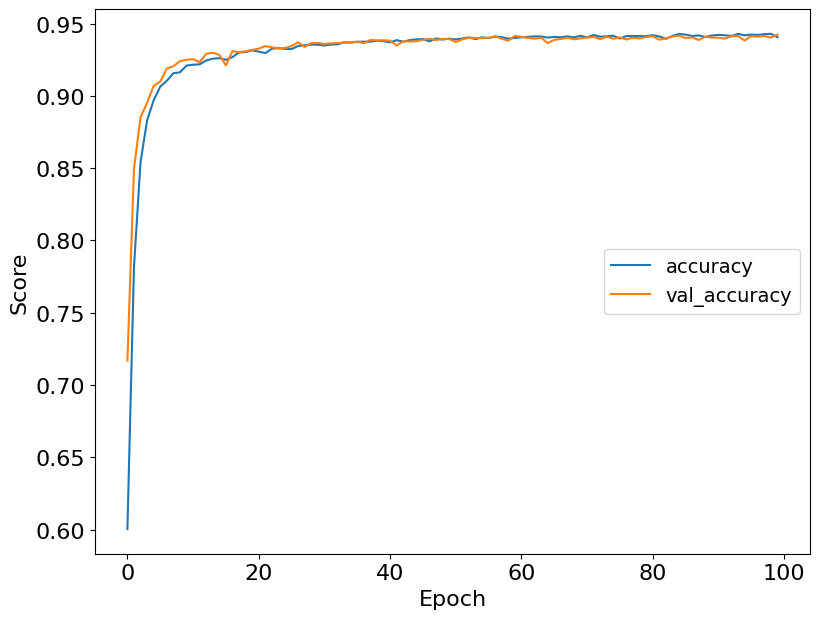

In [26]:
plt.figure(figsize=(8,6))
plt.rcParams.update({'font.size': 16})
plt.plot(pred.history['accuracy'])
plt.plot(pred.history['val_accuracy'])

plt.title('')
plt.ylabel('Score', fontsize=16)
plt.xlabel('Epoch', fontsize=16)

plt.legend(['accuracy', 'val_accuracy'], loc='right',fontsize=14)
plt.tight_layout(pad=0)
plt.savefig('fig.pdf', bbox_inches='tight')

In [32]:
rounded_predictions = model_conv.predict(X_valid, batch_size=128, verbose=0)
rounded_labels=np.argmax(Y_valid, axis=1)
rounded_predictions=np.argmax(rounded_predictions, axis=1)
print(classification_report(rounded_labels,rounded_predictions))
print(confusion_matrix(rounded_labels,rounded_predictions))

              precision    recall  f1-score   support

           0       0.93      0.95      0.94     18054
           1       0.95      0.94      0.95     21946

    accuracy                           0.94     40000
   macro avg       0.94      0.94      0.94     40000
weighted avg       0.94      0.94      0.94     40000

[[17078   976]
 [ 1333 20613]]


In [ ]:
from keras.layers import Dense, Flatten, LSTM, Conv1D, MaxPooling1D, Dropout, Activation,Embedding
from keras.models import Sequential
model_conv = Sequential()
model_conv.add(Embedding(5000, 100, input_length=data.shape[1]))
model_conv.add(Conv1D(512, 2, activation='relu'))
model_conv.add(MaxPooling1D(pool_size=2))
model_conv.add(Activation('relu'))
model_conv.add(Dropout(rate=0.5))
model_conv.add(Flatten())
model_conv.add(Dense(2, activation='softmax'))
model_conv.compile(loss='binary_crossentropy', optimizer='adam',   metrics=['accuracy','mae','mse'])

#Here we train the Network.

pred=model_conv.fit(X_train, Y_train, batch_size =batch_size, epochs =100, verbose =2,validation_data=(X_valid,Y_valid))
pred

Epoch 1/100
1250/1250 - 71s - loss: 0.4438 - accuracy: 0.7554 - mae: 0.2694 - mse: 0.1656 - val_loss: 0.4057 - val_accuracy: 0.7691 - val_mae: 0.2411 - val_mse: 0.1555 - 71s/epoch - 57ms/step
Epoch 2/100


In [ ]:
plt.figure(figsize=(8,6))
plt.rcParams.update({'font.size': 16})
plt.plot(pred.history['accuracy'])
plt.plot(pred.history['val_accuracy'])

plt.title('')
plt.ylabel('Score', fontsize=16)
plt.xlabel('Epoch', fontsize=16)

plt.legend(['accuracy', 'val_accuracy'], loc='right',fontsize=14)
plt.tight_layout(pad=0)
plt.savefig('fig.pdf', bbox_inches='tight')

In [ ]:
rounded_predictions = model_conv.predict(X_valid, batch_size=128, verbose=0)
rounded_labels=np.argmax(Y_valid, axis=1)
rounded_predictions=np.argmax(rounded_predictions, axis=1)
print(classification_report(rounded_labels,rounded_predictions))
print(confusion_matrix(rounded_labels,rounded_predictions))

In [ ]:
from keras.layers import Dense, Flatten, LSTM, Conv1D, MaxPooling1D, Dropout, Activation,Embedding
from keras.models import Sequential
model_conv = Sequential()
model_conv.add(Embedding(1000, 200, input_length=data.shape[1]))
model_conv.add(Conv1D(128, 2, activation='relu'))
model_conv.add(MaxPooling1D(pool_size=2))
model_conv.add(LSTM(100))
model_conv.add(Dense(2, activation='softmax'))
model_conv.compile(loss='binary_crossentropy', optimizer='adam',   metrics=['accuracy','mae','mse'])

#Here we train the Network.
pred=model_conv.fit(X_train, Y_train, batch_size =batch_size, epochs =100, verbose =2,validation_data=(X_valid,Y_valid))
pred

In [ ]:
plt.figure(figsize=(8,6))
plt.rcParams.update({'font.size': 16})
plt.plot(pred.history['accuracy'])
plt.plot(pred.history['val_accuracy'])

plt.title('')
plt.ylabel('Score', fontsize=16)
plt.xlabel('Epoch', fontsize=16)

plt.legend(['accuracy', 'val_accuracy'], loc='right',fontsize=14)
plt.tight_layout(pad=0)
plt.savefig('fig.pdf', bbox_inches='tight')

In [ ]:
rounded_predictions = model_conv.predict(X_valid, batch_size=128, verbose=0)
rounded_labels=np.argmax(Y_valid, axis=1)
rounded_predictions=np.argmax(rounded_predictions, axis=1)
print(classification_report(rounded_labels,rounded_predictions))
print(confusion_matrix(rounded_labels,rounded_predictions))

In [50]:
# t-test
from math import sqrt
from numpy.random import seed
from numpy.random import randn
from numpy import mean
from scipy.stats import t

# function for calculating the t-test for two dependent samples
def dependent_ttest(data1, data2, alpha):
	# calculate means
	mean1, mean2 = mean(data1), mean(data2)
	# number of paired samples
	n = len(data1)
	# sum squared difference between observations
	d1 = sum([(data1[i]-data2[i])**2 for i in range(n)])
	# sum difference between observations
	d2 = sum([data1[i]-data2[i] for i in range(n)])
	# standard deviation of the difference between means
	sd = sqrt((d1 - (d2**2 / n)) / (n - 1))
	# standard error of the difference between the means
	sed = sd / sqrt(n)
	# calculate the t statistic
	t_stat = (mean1 - mean2) / sed
	# degrees of freedom
	df = n - 1
	# calculate the critical value
	cv = t.ppf(1.0 - alpha, df)
	# calculate the p-value
	p = (1.0 - t.cdf(abs(t_stat), df)) * 2.0
	# return everything
	return t_stat, df, cv, p

# seed the random number generator
seed(1)


WAF = [0.58,
0.70,
0.70,
0.58,
0.58,
0.61,
0.61,
0.58

]
WSP = [0.64,
0.76,
0.79,
0.52,
0.48,
0.79,
0.67,
0.48

]
WAFSE = [0.91,
0.91,
0.91,
0.91,
0.91,
0.91,
0.91,
0.91

]

WAFSP = [0.97,
0.97,
0.97,
0.79,
0.97,
0.97,
0.97,
0.97


]


# calculate the t test
alpha =0.3
t_stat, df, cv, p = dependent_ttest(WAFSP, WAFSE, alpha)
print('t=%.3f, df=%d' % (t_stat, df))
print('cv=%.3f'%cv)
# interpret via critical value
if abs(t_stat) <= cv:
	print('Accept null hypothesis that the means are equal.')
else:
	print('Reject the null hypothesis that the means are not equal.')


t=1.667, df=7
cv=0.549
Reject the null hypothesis that the means are not equal.


In [51]:
# t-test
from math import sqrt
from numpy.random import seed
from numpy.random import randn
from numpy import mean
from scipy.stats import t

# function for calculating the t-test for two dependent samples
def dependent_ttest(data1, data2, alpha):
	# calculate means
	mean1, mean2 = mean(data1), mean(data2)
	# number of paired samples
	n = len(data1)
	# sum squared difference between observations
	d1 = sum([(data1[i]-data2[i])**2 for i in range(n)])
	# sum difference between observations
	d2 = sum([data1[i]-data2[i] for i in range(n)])
	# standard deviation of the difference between means
	sd = sqrt((d1 - (d2**2 / n)) / (n - 1))
	# standard error of the difference between the means
	sed = sd / sqrt(n)
	# calculate the t statistic
	t_stat = (mean1 - mean2) / sed
	# degrees of freedom
	df = n - 1
	# calculate the critical value
	cv = t.ppf(1.0 - alpha, df)
	# calculate the p-value
	p = (1.0 - t.cdf(abs(t_stat), df)) * 2.0
	# return everything
	return t_stat, df, cv, p

# seed the random number generator
seed(1)


WAF = [1 ,1 ,1 ,1 ,0.995 ,0.992 ,0.992, 0.992 ,0.96 ,0.941, 0.94, 0.94]
WSP = [0.997, 0.995, 0.995, 0.995, 0.982, 0.973, 0.973, 0.973, 0.933, 0.912, 0.90, 0.900]


# calculate the t test
alpha =0.3
t_stat, df, cv, p = dependent_ttest(WAF, WSP, alpha)
print('t=%.3f, df=%d' % (t_stat, df))
print('cv=%.3f'%cv)
# interpret via critical value
if abs(t_stat) <= cv:
	print('Accept null hypothesis that the means are equal.')
else:
	print('Reject the null hypothesis that the means are not equal.')


t=4.889, df=11
cv=0.540
Reject the null hypothesis that the means are not equal.


In [15]:
array1 = [[1840  ,  1],[  47  ,372]]
RF = pd.DataFrame(array1, index = [i for i in "01"],
                  columns = [i for i in "01"])

array2 =[[1825 ,  16],[  26 , 393]]
GBM = pd.DataFrame(array2, index = [i for i in "01"],
                  columns = [i for i in "01"])

array3 = [[1817  , 24],[  22  ,397]]
SVC = pd.DataFrame(array3, index = [i for i in "01"],
                  columns = [i for i in "01"])

array4 = [[1478 , 363],[  59 , 360]]
NB = pd.DataFrame(array4, index = [i for i in "01"],
                  columns = [i for i in "01"])

array5 = [[1822 ,  19],[  26 , 393]]
LR = pd.DataFrame(array5, index = [i for i in "01"],
                  columns = [i for i in "01"])

array6 = [[1827 ,  14],[  26 , 393]]
EM = pd.DataFrame(array6, index = [i for i in "01"],
                  columns = [i for i in "01"])



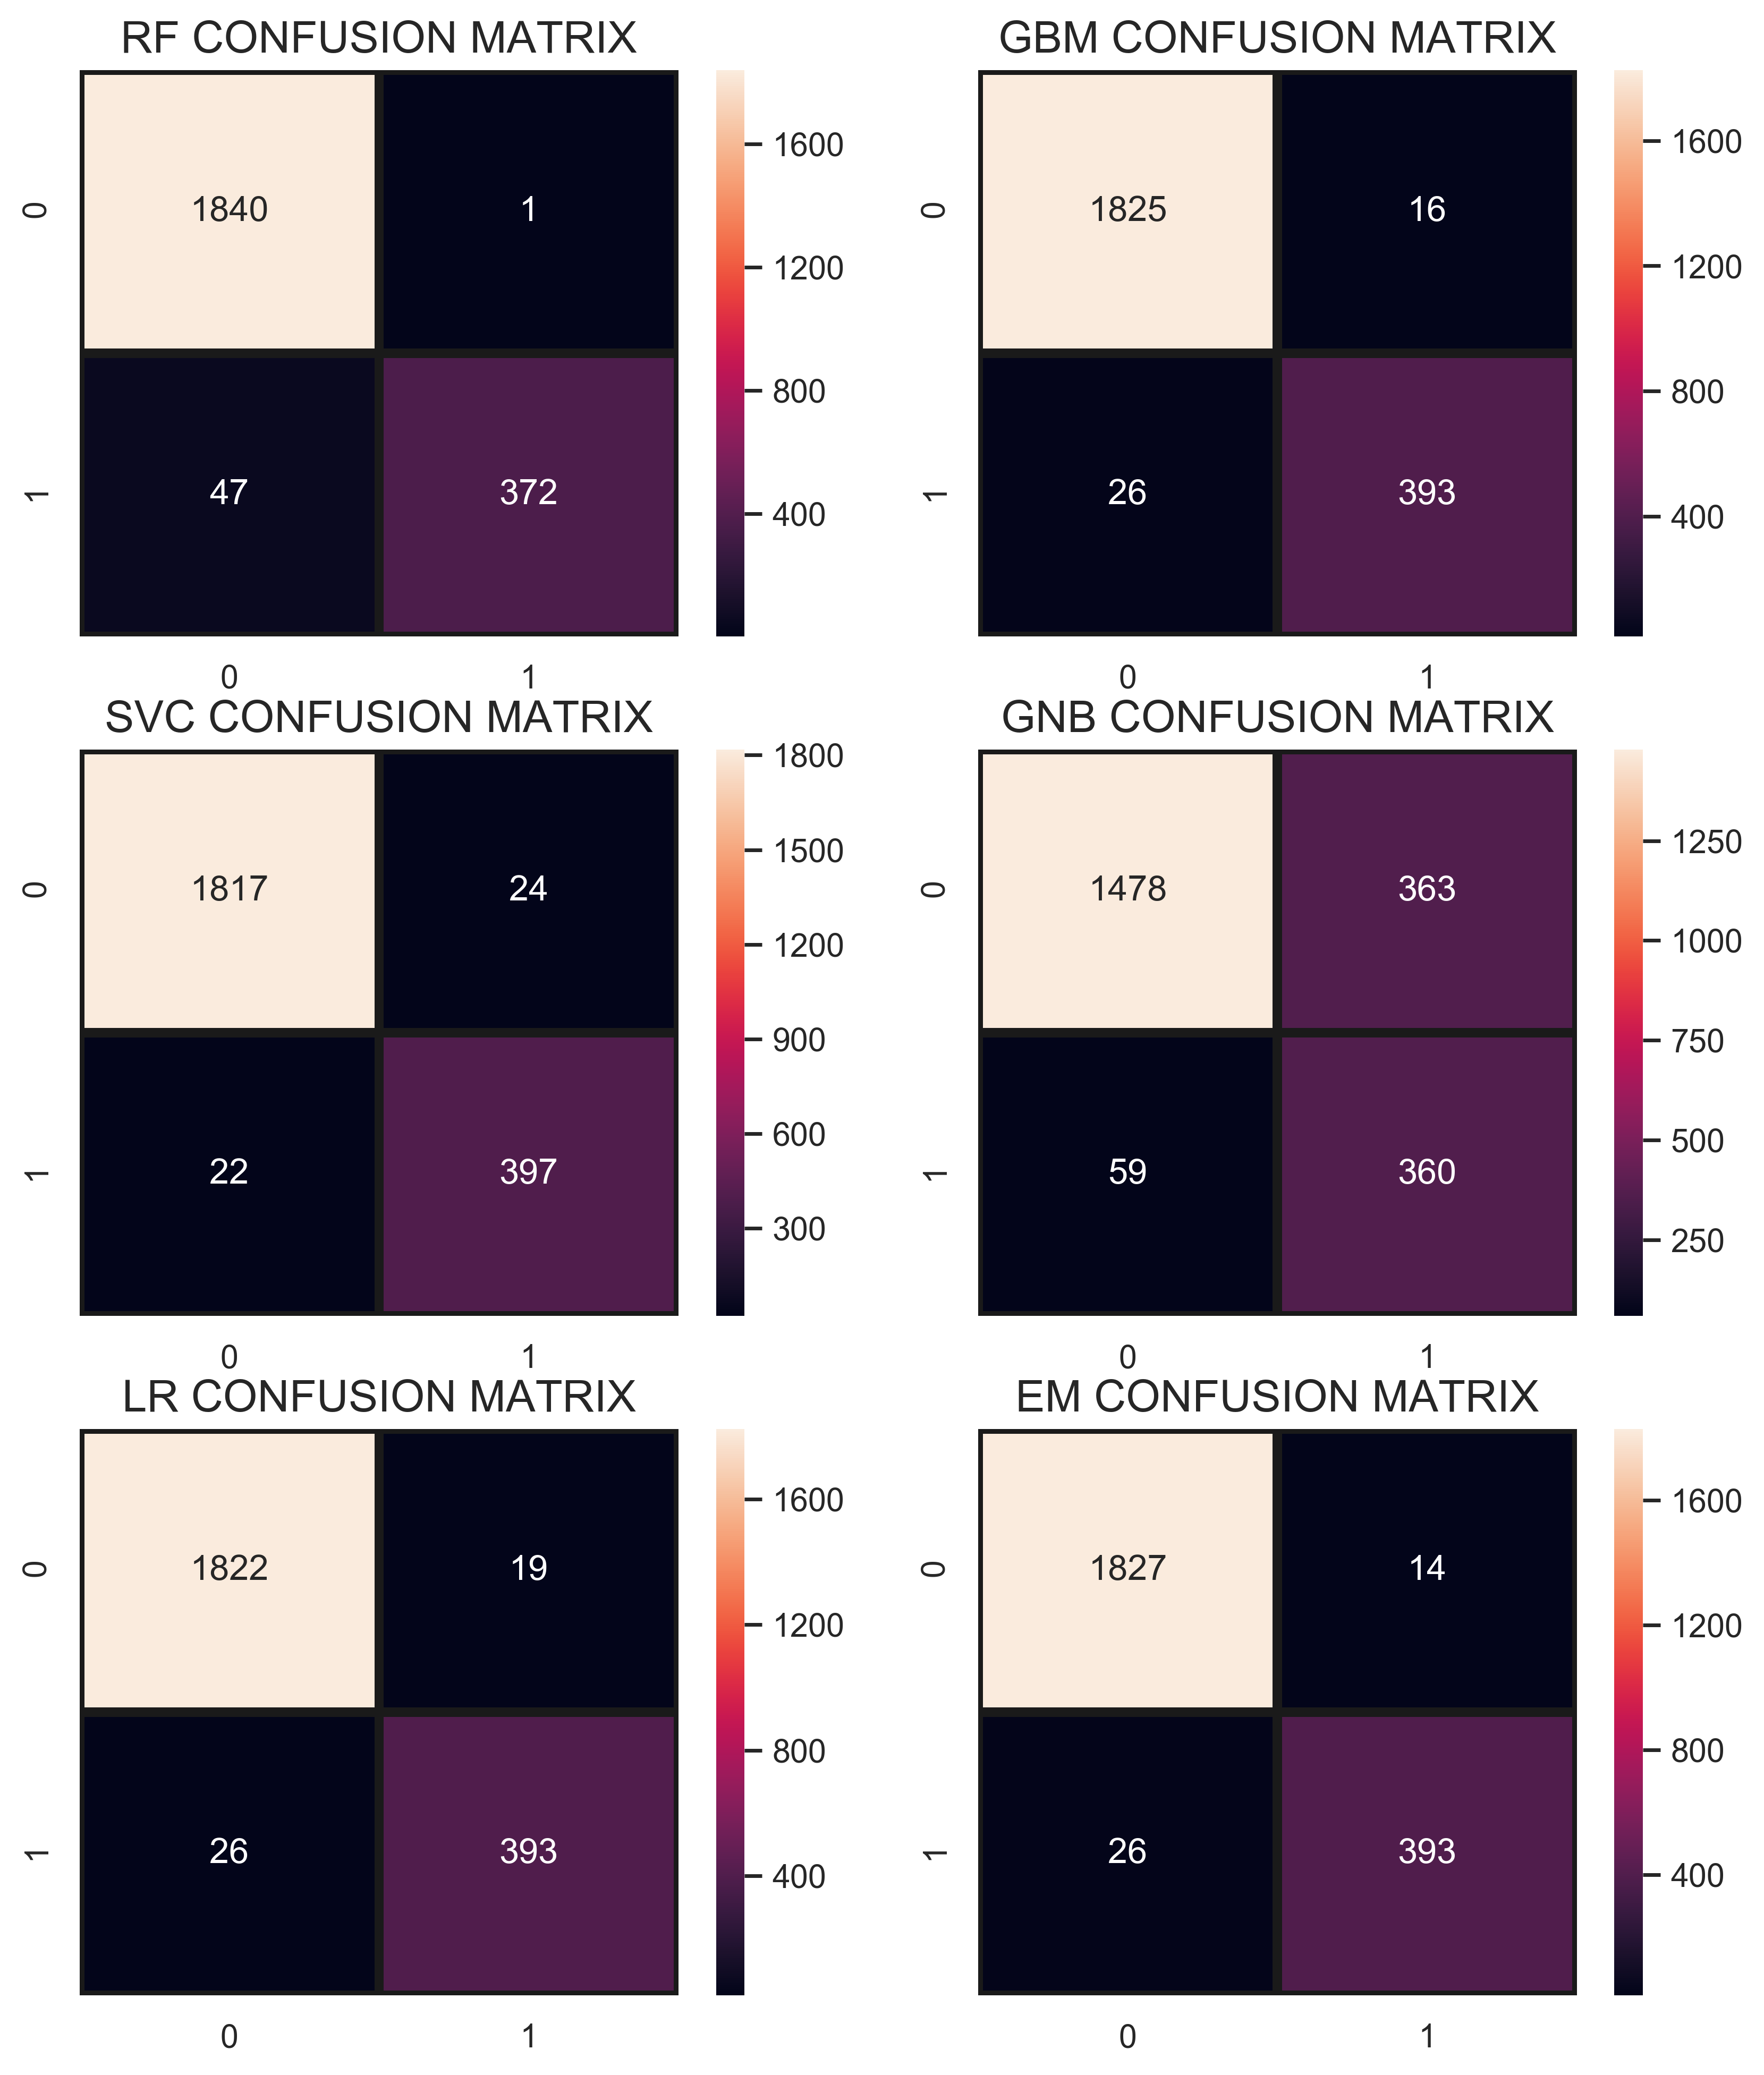

In [16]:
i=1
def plot_sub_sentiment(Airline,A):
    sns.set()
    #tmp = rfc.fit(X_train, y_train.ravel())
    sns.heatmap(Airline,annot=True,fmt = "d",linecolor="k",linewidths=3)
    plt.title(A +" CONFUSION MATRIX",fontsize=15)

plt.figure(1,figsize=(10, 12),dpi=400)
plt.subplot(321) 
plot_sub_sentiment(RF,'RF')
plt.subplot(322)
plot_sub_sentiment(GBM,'GBM')
plt.subplot(323)
plot_sub_sentiment(SVC,'SVC') 
plt.subplot(324) 
plot_sub_sentiment(NB,'GNB')
plt.subplot(325)
plot_sub_sentiment(LR,'LR') 
plt.subplot(326) 
plot_sub_sentiment(EM,'EM')

plt.savefig('conf3.png')
